# CIFAR-10 data loading and exploratory analysis

This notebook loads CIFAR-10 through `tensorflow.keras.datasets` at runtime.
It uses the complete official split: 50,000 training images and 10,000 test
images. The test set is reserved for final evaluation and is not used to
calculate normalization statistics.

Images are loaded as NHWC RGB arrays, then normalized using training-set
channel statistics and converted to NCHW for the NumPy CNN.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from tensorflow.keras.datasets import cifar10

PROJECT_ROOT = next(
    (
        candidate
        for candidate in (Path.cwd(), *Path.cwd().parents)
        if (candidate / "configs" / "cifar10_baseline.json").is_file()
    ),
    Path.cwd(),
)

CONFIG_PATH = PROJECT_ROOT / "configs" / "cifar10_baseline.json"

if not CONFIG_PATH.is_file():
    raise FileNotFoundError(
        f"Could not locate baseline config: {CONFIG_PATH}"
    )

with CONFIG_PATH.open(encoding="utf-8") as file:
    config = json.load(file)

dataset_config = config["dataset"]
class_names = dataset_config["class_names"]
num_classes = dataset_config["num_classes"]

assert dataset_config["name"] == "cifar10"
assert dataset_config["allow_subsampling"] is False
assert len(class_names) == num_classes

print(f"Loaded configuration: {CONFIG_PATH}")
print(f"Dataset: {dataset_config['name']}")
print(f"Classes: {num_classes}")

Loaded configuration: c:\Users\hp\Documents\GitHub\visual-feature-learning\configs\cifar10_baseline.json
Dataset: cifar10
Classes: 10


In [2]:
# Keras fetches CIFAR-10 at runtime and may cache it outside the repository.
(train_images_raw, y_train_raw), (
    test_images_raw,
    y_test_raw,
) = cifar10.load_data()

y_train = y_train_raw.squeeze().astype(np.int64)
y_test = y_test_raw.squeeze().astype(np.int64)

assert train_images_raw.shape == (
    dataset_config["expected_train_samples"],
    32,
    32,
    3,
)
assert test_images_raw.shape == (
    dataset_config["expected_test_samples"],
    32,
    32,
    3,
)
assert train_images_raw.dtype == np.uint8
assert test_images_raw.dtype == np.uint8
assert y_train.shape == (
    dataset_config["expected_train_samples"],
)
assert y_test.shape == (
    dataset_config["expected_test_samples"],
)

assert np.all((0 <= y_train) & (y_train < num_classes))
assert np.all((0 <= y_test) & (y_test < num_classes))

print(
    "Train images:",
    train_images_raw.shape,
    train_images_raw.dtype,
)
print("Train labels:", y_train.shape, y_train.dtype)
print(
    "Test images:",
    test_images_raw.shape,
    test_images_raw.dtype,
)
print("Test labels:", y_test.shape, y_test.dtype)

Train images: (50000, 32, 32, 3) uint8
Train labels: (50000,) int64
Test images: (10000, 32, 32, 3) uint8
Test labels: (10000,) int64


In [3]:
train_class_counts = np.bincount(
    y_train,
    minlength=num_classes,
)
test_class_counts = np.bincount(
    y_test,
    minlength=num_classes,
)

print("Training images per class:")
for name, count in zip(
    class_names,
    train_class_counts,
    strict=False,
):
    print(f"  {name:>10}: {count}")

print("\nTest images per class:")
for name, count in zip(
    class_names,
    test_class_counts,
    strict=False,
):
    print(f"  {name:>10}: {count}")

# The official CIFAR-10 split is balanced.
np.testing.assert_array_equal(
    train_class_counts,
    5000,
)
np.testing.assert_array_equal(
    test_class_counts,
    1000,
)

print("\nFull split and balanced class counts: OK")

Training images per class:
    airplane: 5000
  automobile: 5000
        bird: 5000
         cat: 5000
        deer: 5000
         dog: 5000
        frog: 5000
       horse: 5000
        ship: 5000
       truck: 5000

Test images per class:
    airplane: 1000
  automobile: 1000
        bird: 1000
         cat: 1000
        deer: 1000
         dog: 1000
        frog: 1000
       horse: 1000
        ship: 1000
       truck: 1000

Full split and balanced class counts: OK


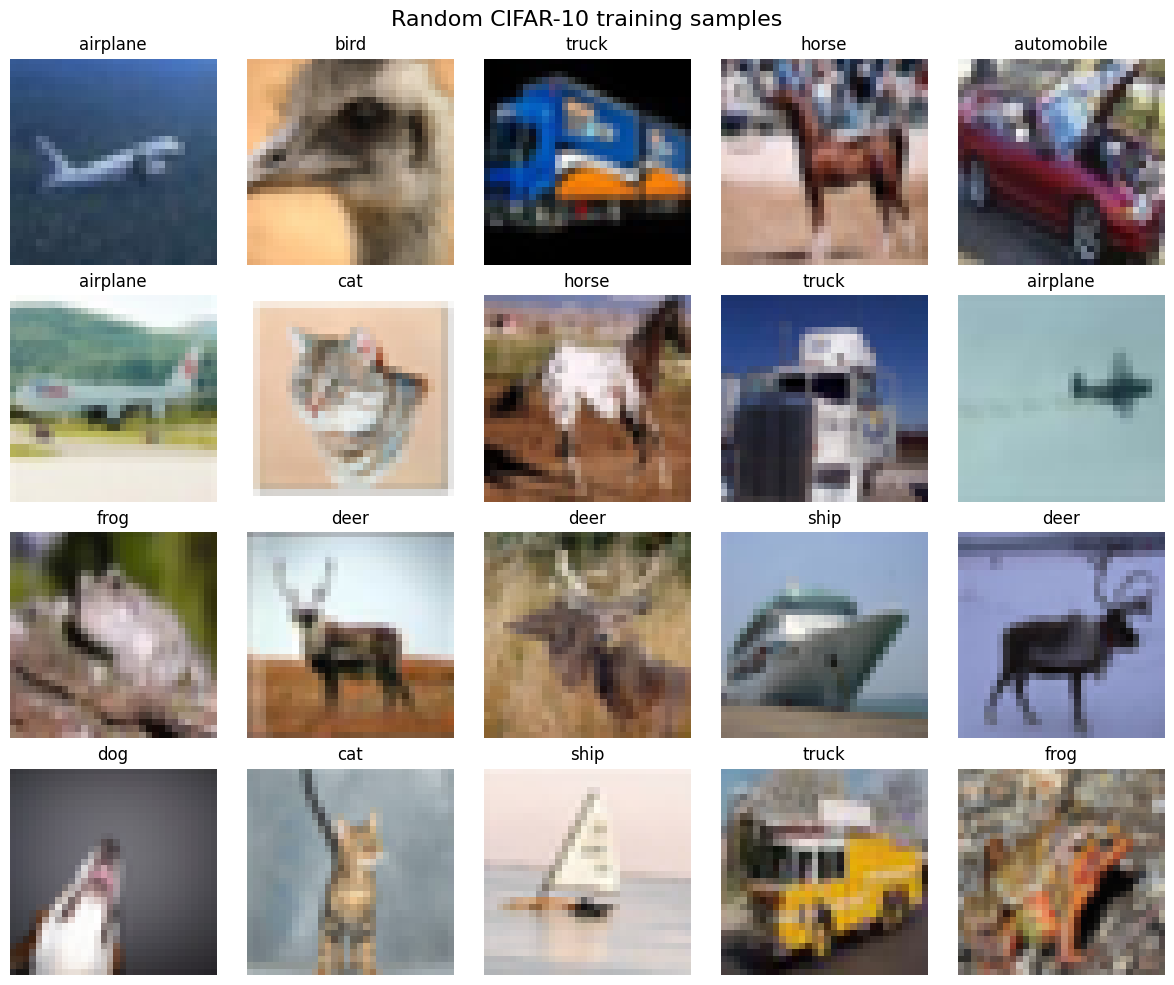

In [4]:
rng = np.random.default_rng(
    config["project"]["seed"]
)

sample_indices = rng.choice(
    len(train_images_raw),
    size=20,
    replace=False,
)

fig, axes = plt.subplots(
    4,
    5,
    figsize=(12, 10),
)

for ax, index in zip(
    axes.flat,
    sample_indices,
    strict=False,
):
    ax.imshow(train_images_raw[index])
    ax.set_title(class_names[y_train[index]])
    ax.axis("off")

fig.suptitle(
    "Random CIFAR-10 training samples",
    fontsize=16,
)
fig.tight_layout()
plt.show()

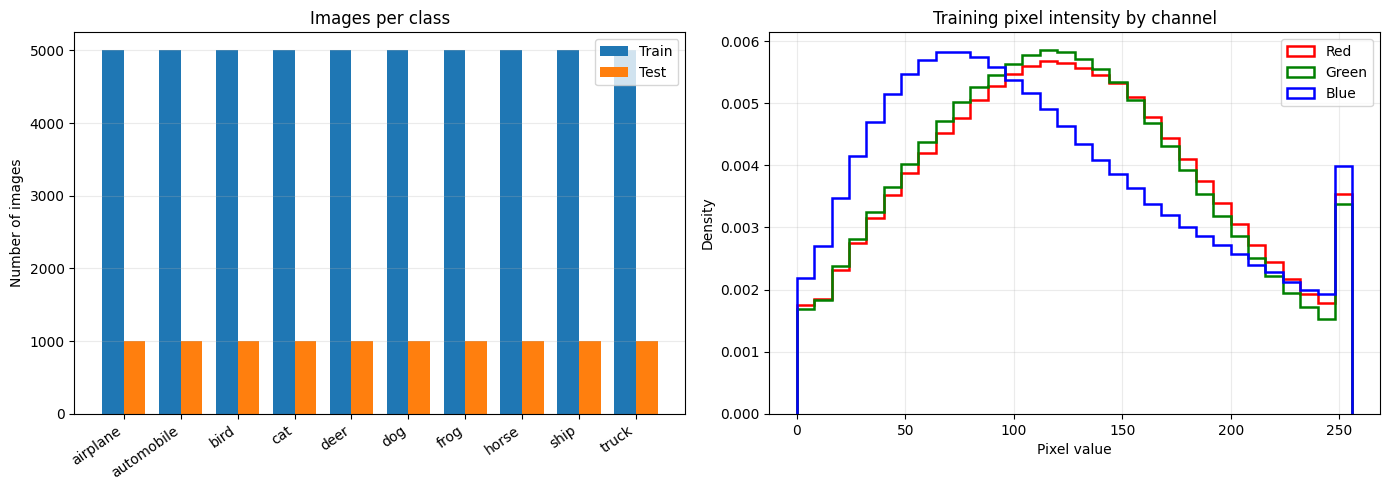

In [5]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

positions = np.arange(num_classes)
bar_width = 0.38

axes[0].bar(
    positions - bar_width / 2,
    train_class_counts,
    width=bar_width,
    label="Train",
)
axes[0].bar(
    positions + bar_width / 2,
    test_class_counts,
    width=bar_width,
    label="Test",
)
axes[0].set_xticks(
    positions,
    class_names,
    rotation=35,
    ha="right",
)
axes[0].set_ylabel("Number of images")
axes[0].set_title("Images per class")
axes[0].legend()
axes[0].grid(
    axis="y",
    alpha=0.25,
)

channel_names = [
    "Red",
    "Green",
    "Blue",
]
channel_colors = [
    "red",
    "green",
    "blue",
]

for channel, (name, color) in enumerate(
    zip(
        channel_names,
        channel_colors,
        strict=False,
    )
):
    values = train_images_raw[..., channel].ravel()

    axes[1].hist(
        values,
        bins=32,
        range=(0, 256),
        density=True,
        histtype="step",
        linewidth=1.8,
        color=color,
        label=name,
    )

axes[1].set_xlabel("Pixel value")
axes[1].set_ylabel("Density")
axes[1].set_title(
    "Training pixel intensity by channel"
)
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.tight_layout()
plt.show()

In [6]:
# Calculate training-only statistics after scaling uint8 pixels to [0, 1].
train_mean = (
    train_images_raw.astype(np.float64).mean(
        axis=(0, 1, 2)
    )
    / 255.0
)

train_std = (
    train_images_raw.astype(np.float64).std(
        axis=(0, 1, 2)
    )
    / 255.0
)

configured_mean = np.asarray(
    dataset_config["normalization"]["mean"],
)
configured_std = np.asarray(
    dataset_config["normalization"]["std"],
)

print(
    "Measured training channel means:",
    train_mean,
)
print(
    "Configured channel means:",
    configured_mean,
)
print(
    "Measured training channel stds:",
    train_std,
)
print(
    "Configured channel stds:",
    configured_std,
)

np.testing.assert_allclose(
    train_mean,
    configured_mean,
    atol=0.01,
)
np.testing.assert_allclose(
    train_std,
    configured_std,
    atol=0.01,
)

mean = configured_mean.reshape(
    1,
    1,
    1,
    3,
).astype(np.float32)

std = configured_std.reshape(
    1,
    1,
    1,
    3,
).astype(np.float32)

x_train_nhwc = (
    train_images_raw.astype(np.float32)
    / 255.0
)
x_test_nhwc = (
    test_images_raw.astype(np.float32)
    / 255.0
)

x_train_nhwc = (
    x_train_nhwc - mean
) / std
x_test_nhwc = (
    x_test_nhwc - mean
) / std

# Convert NHWC images to contiguous NCHW tensors.
x_train = np.ascontiguousarray(
    x_train_nhwc.transpose(
        0,
        3,
        1,
        2,
    )
)
x_test = np.ascontiguousarray(
    x_test_nhwc.transpose(
        0,
        3,
        1,
        2,
    )
)

assert x_train.shape == (
    50000,
    3,
    32,
    32,
)
assert x_test.shape == (
    10000,
    3,
    32,
    32,
)
assert x_train.dtype == np.float32
assert x_test.dtype == np.float32
assert y_train.shape == (50000,)
assert y_test.shape == (10000,)

print(
    "\nPreprocessed training data:",
    x_train.shape,
    x_train.dtype,
)
print(
    "Preprocessed test data:",
    x_test.shape,
    x_test.dtype,
)
print(
    "Training data range after standardization:",
    float(x_train.min()),
    "to",
    float(x_train.max()),
)

Measured training channel means: [0.49139968 0.48215841 0.44653091]
Configured channel means: [0.4914 0.4822 0.4465]
Measured training channel stds: [0.24703223 0.24348513 0.26158784]
Configured channel stds: [0.247 0.243 0.261]

Preprocessed training data: (50000, 3, 32, 32) float32
Preprocessed test data: (10000, 3, 32, 32) float32
Training data range after standardization: -1.9894737005233765 to 2.130864143371582


In [7]:
# Plot RGB channels as three separate 3D surfaces.
sample_index = int(sample_indices[0])

image_01 = (
    train_images_raw[sample_index].astype(
        np.float32
    )
    / 255.0
)

x_coordinates = np.arange(
    image_01.shape[1]
)
y_coordinates = np.arange(
    image_01.shape[0]
)

fig = make_subplots(
    rows=1,
    cols=3,
    specs=[
        [
            {"type": "surface"},
            {"type": "surface"},
            {"type": "surface"},
        ]
    ],
    subplot_titles=(
        "Red channel",
        "Green channel",
        "Blue channel",
    ),
)

for channel, colorscale, column in [
    (0, "Reds", 1),
    (1, "Greens", 2),
    (2, "Blues", 3),
]:
    fig.add_trace(
        go.Surface(
            x=x_coordinates,
            y=y_coordinates,
            z=image_01[:, :, channel],
            colorscale=colorscale,
            cmin=0,
            cmax=1,
            showscale=False,
            name=channel_names[channel],
        ),
        row=1,
        col=column,
    )

fig.update_layout(
    title=(
        "3D RGB channel intensities — "
        f"{class_names[y_train[sample_index]]}"
    ),
    height=550,
    width=1100,
    margin={
        "l": 10,
        "t": 80,
        "r": 10,
        "b": 10,
    },
)

for scene_name in (
    "scene",
    "scene2",
    "scene3",
):
    fig.layout[scene_name].update(
        xaxis_title="Pixel x",
        yaxis_title="Pixel y",
        zaxis_title="Intensity",
        zaxis={
            "range": [0, 1],
        },
        aspectmode="manual",
        aspectratio={
            "x": 1,
            "y": 1,
            "z": 0.5,
        },
    )

fig.show()

In [8]:
assert len(x_train) == (
    dataset_config["expected_train_samples"]
)
assert len(x_test) == (
    dataset_config["expected_test_samples"]
)
assert x_train.shape[1:] == tuple(
    dataset_config["input_shape"]
)
assert x_test.shape[1:] == tuple(
    dataset_config["input_shape"]
)
assert int(train_class_counts.sum()) == 50000
assert int(test_class_counts.sum()) == 10000

print("EDA complete.")
print(
    "The full official CIFAR-10 split is "
    "loaded and ready for training."
)
print(
    "Use x_train and y_train for training "
    "and x_test and y_test for final evaluation."
)

EDA complete.
The full official CIFAR-10 split is loaded and ready for training.
Use x_train and y_train for training and x_test and y_test for final evaluation.
